# Variational JEPA: a world model that knows when it is unsure

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/varjepa.ipynb)

[Variational JEPA](https://arxiv.org/abs/2601.14354) ([code](https://github.com/YongchaoHuang/VJEPA)) makes the JEPA predictor probabilistic: it outputs a Gaussian over the next embedding, trained by the likelihood of targets drawn around an EMA target encoder, with a KL term toward a standard normal. Its variance says how far off a prediction is likely to be.

Here a macaw learns to fly a sky split by a rock wall with one gap, then plans on its mean and on sampled futures.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
from functools import partial

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import Macaw
from torch_world.models import VariationalJEPA
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
SKIP = 5  # the model sees every 5th frame and the 5 actions in between

## Data and model
The macaw flies at random, with no goal in mind, through a sky split by a rock wall with one gap. The encoder and causal predictor follow LeWM; the predictor's head outputs a mean and a log-variance.

In [3]:
data = Macaw(batch_size=1024, rooms=True, device=device).collect(40, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=4, frameskip=SKIP), batch_size=128, shuffle=True, drop_last=True)

encoder = CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)
model = VariationalJEPA(encoder, action_dim=2 * SKIP, embed_dim=128, history=3, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512).to(device)
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.1f}M parameters")

2.4M parameters


## Train
Negative log-likelihood of the sampled targets, 0.01 × KL toward N(0, I), and SIGReg against collapse. The target encoder follows the online one by EMA.

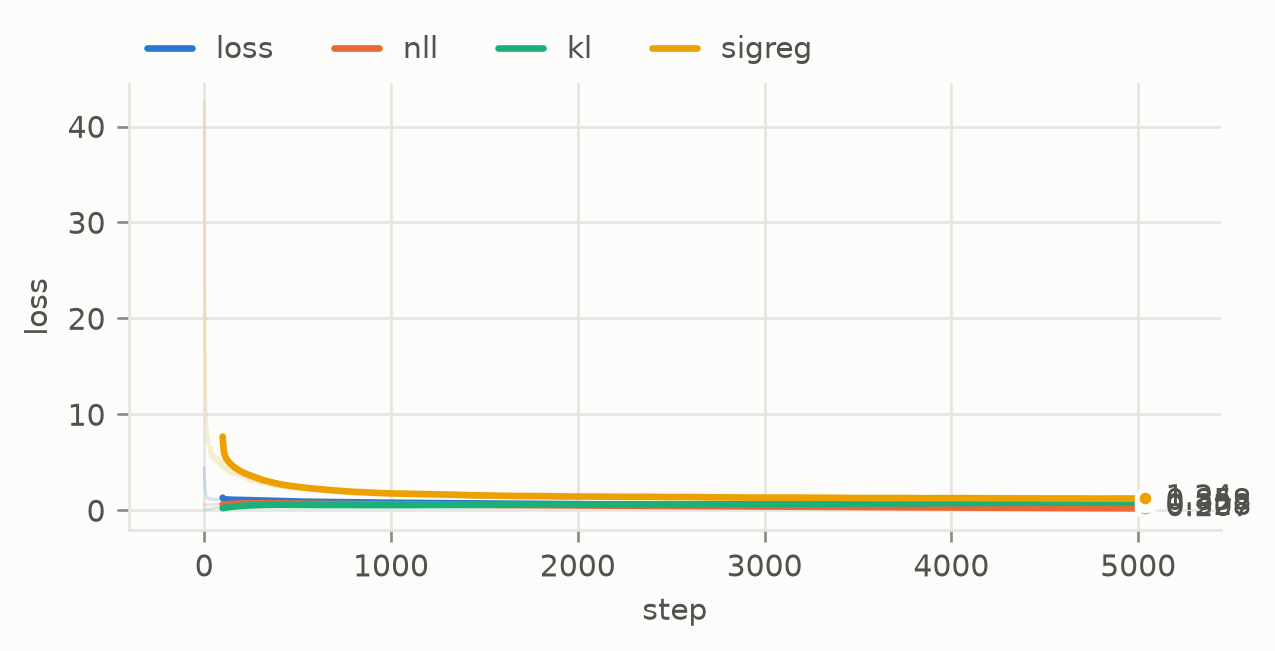

In [4]:
log = fit(model, loader, epochs=30, lr=3e-4, step=lambda: model.update_target(0.99))
plots.curves(log, smooth=100, logy=False)

## Is the variance calibrated?
On held-out episodes, sort the predictions into ten bins of predicted variance and compare with the actual error of the mean against the real next embedding. A useful variance grows with the error.

correlation of predicted variance and error: 0.52


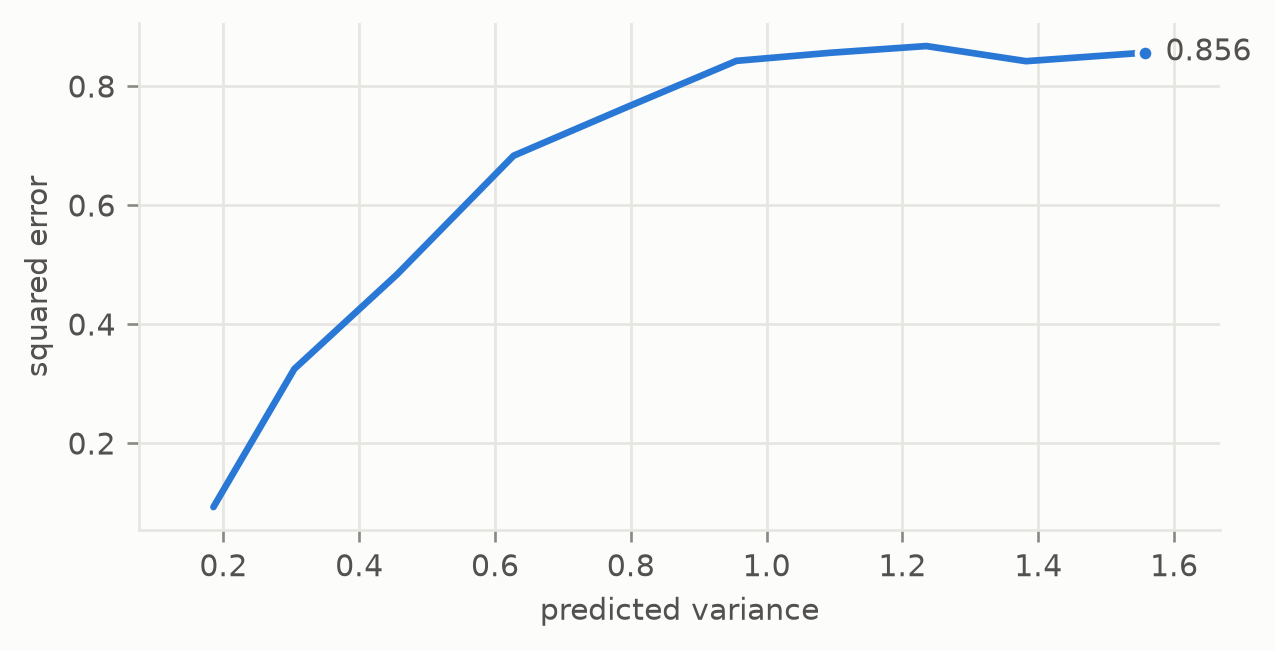

In [5]:
held_out = Macaw(batch_size=512, rooms=True, device=device).collect(20, generator=torch.Generator().manual_seed(5))
batch = next(iter(DataLoader(TrajectoryDataset(held_out, window=4, frameskip=SKIP), batch_size=4096)))
with torch.no_grad():
    z = model.encode(batch["pixels"])
    mean, logvar = model.distribution(z[:, :3], batch["actions"][:, :3])
    target = model.encode(batch["pixels"][:, 1:], model.target_encoder)
variance, error = logvar.exp().mean(-1).flatten().cpu(), (mean - target).square().mean(-1).flatten().cpu()

bins = variance.argsort().chunk(10)
print(f"correlation of predicted variance and error: {torch.corrcoef(torch.stack([variance, error]))[0, 1]:.2f}")
plots.curves({"error": ([variance[i].mean() for i in bins], [error[i].mean() for i in bins])}, smooth=1, logy=False, xlabel="predicted variance", ylabel="squared error")

## Plan toward goal images across the wall
CEM over 5 chunks of 5 actions, on the predicted **mean** (the paper's MAP plan) and on **sampled** futures, one per candidate. The policy runs the first chunk and plans again.

In [6]:
env = Macaw(batch_size=32, rooms=True, device=device)
start, goal = env.tasks(generator=torch.Generator().manual_seed(1))  # start and goal on opposite sides of the wall
goal_images = env.render(goal)

planner = CEM(horizon=5, action_dim=2 * SKIP, num_samples=300, num_elites=30, bounds=(-1, 1))
policies = {
    "mean + CEM": evaluation.goal_policy(model, planner, goal_images, action_dim=2),
    "samples + CEM": evaluation.goal_policy(model, partial(planner, sample=True), goal_images, action_dim=2),
    "random actions": evaluation.random_policy(env),
}
result = evaluation.goal_reaching(env, policies, start, goal, steps=50, success="reached")
result

                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
mean + CEM         47% [31%, 64%]      47%    18.8            0.23     0.547   0.131       0.425        702
samples + CEM       12% [5%, 28%]      12%    13.8           0.479   -0.0543  0.0238       0.424        706
random actions       3% [1%, 16%]       3%       6           0.434    0.0194 0.00244        1.01      0.106

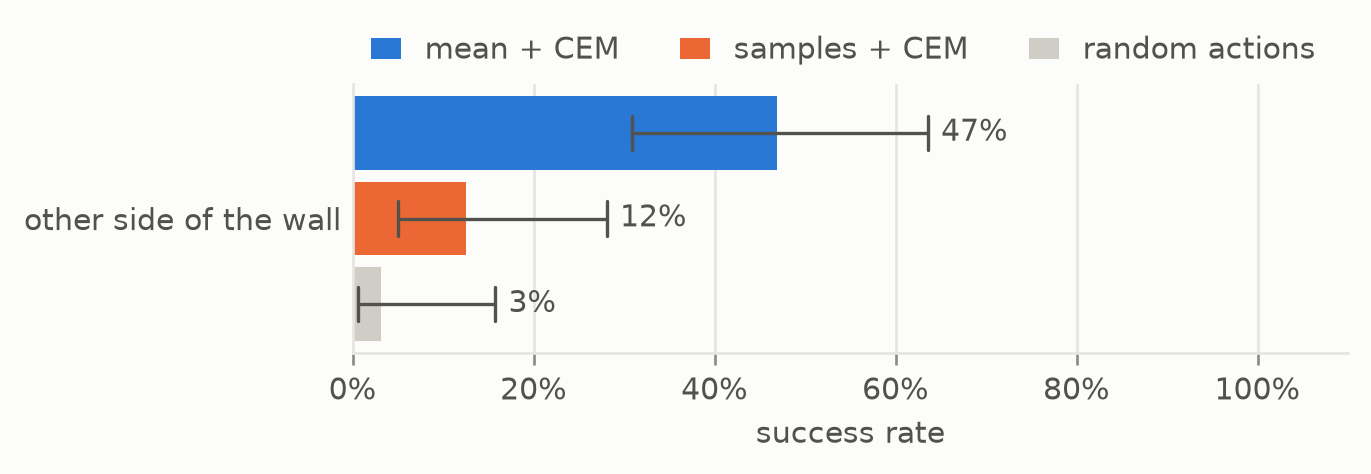

In [7]:
plots.bars({"other side of the wall": result.intervals()}, xlabel="success rate", baseline="random actions")

## Summary
Variational JEPA predicts a distribution over the next embedding, without reconstructing pixels. The calibration curve shows whether its variance tracks its error. When the noise hardly depends on the action, the paper shows that planning on the mean and on samples rank actions alike; the bars compare both.